# **Лабораторная 4. Определение тренда, неаналитическое сглаживание ряда**

> - **Предмет**: Математические методы анализа экономических процессов
> - **Студент**: Руденко Андрей Артемович
> - **Группа**: М9125-01.04.02МКТ

## Цель работы
1. Определить наличие тренда в ряду методом сравнения средних и методом Фостера–Стюарта
2. Провести неаналитическое сглаживание ряда и составить прогноз на два периода

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## Данные *(Вариант 16)*

Просроченная кредиторская задолженность организаций поставщикам и подрядчикам на конец года за 1995–2021 гг., млрд руб. До 1998 г. значения даны в трлн неденоминированных рублей, что равно млрд рублей после деноминации, поэтому ряд однороден.

In [2]:
raw = pd.read_excel('fin_sost_org.xlsx.ods', engine='odf', sheet_name='4', header=None)
y = raw.iloc[6:33].set_index(1)[5].astype(float)
y.index = y.index.astype(int)
y.index.name = 'Год'
n = len(y)
y

Год
1995     122.0
1996     246.0
1997     345.0
1998     586.0
1999     619.0
2000     712.0
2001     754.0
2002     710.0
2003     652.0
2004     569.0
2005     516.0
2006     475.0
2007     554.0
2008     716.0
2009     681.0
2010     721.0
2011     884.0
2012     911.0
2013    1157.0
2014    1451.0
2015    1621.0
2016    1969.0
2017    1961.0
2018    2386.0
2019    2645.0
2020    2686.0
2021    2349.0
Name: 5, dtype: float64

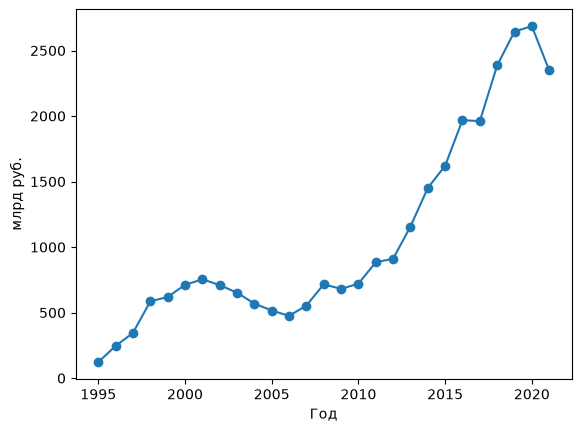

In [3]:
plt.plot(y, marker='o')
plt.xlabel('Год')
plt.ylabel('млрд руб.')
plt.show()

## 4.1. Определение наличия тренда

### Метод сравнения средних

Ряд делится на две половины, для каждой считается среднее и дисперсия. Сначала F-критерием Фишера проверяется однородность дисперсий, затем t-критерием Стьюдента — равенство средних. Уровень значимости 0.05.
$$F = \frac{\sigma_{б}^2}{\sigma_{м}^2}, \qquad t = \frac{|\bar{y}_1 - \bar{y}_2|}{\sigma \sqrt{\frac{1}{n_1} + \frac{1}{n_2}}}, \qquad \sigma = \sqrt{\frac{(n_1 - 1)\sigma_1^2 + (n_2 - 1)\sigma_2^2}{n_1 + n_2 - 2}}$$

In [4]:
y1, y2 = y.iloc[:n // 2], y.iloc[n // 2:]
n1, n2 = len(y1), len(y2)
var1, var2 = y1.var(), y2.var()
print(f'Средние: {y1.mean():.1f}, {y2.mean():.1f}')
print(f'Дисперсии: {var1:.1f}, {var2:.1f}')

if var1 > var2:
    F, F_crit = var1 / var2, stats.f.ppf(0.95, n1 - 1, n2 - 1)
else:
    F, F_crit = var2 / var1, stats.f.ppf(0.95, n2 - 1, n1 - 1)
print(f'F = {F:.2f}, F табл = {F_crit:.2f}')

sigma = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2))
t = abs(y1.mean() - y2.mean()) / (sigma * np.sqrt(1 / n1 + 1 / n2))
t_crit = stats.t.ppf(0.975, n1 + n2 - 2)
print(f't = {t:.2f}, t табл = {t_crit:.2f}')

Средние: 527.7, 1581.3
Дисперсии: 35686.2, 562824.8
F = 15.77, F табл = 2.66
t = 4.91, t табл = 2.06


F = 15.77 больше табличного 2.66: дисперсии половин ряда неоднородны, во второй половине разброс уровней намного больше. t = 4.91 больше табличного 2.06: средние половин (527.7 и 1581.3) различаются значимо. Тренд есть.

### Метод Фостера–Стюарта

Каждый уровень сравнивается со всеми предыдущими: $k_t = 1$, если он больше всех предыдущих, $l_t = 1$, если меньше всех предыдущих. По ним считаются $d$ — характеристика тренда среднего и $s$ — характеристика тренда дисперсии.
$$d = \sum_{t=2}^{n} (k_t - l_t), \qquad s = \sum_{t=2}^{n} (k_t + l_t)$$
$$t_d = \frac{|d|}{\sigma_1}, \qquad t_s = \frac{|s - \mu|}{\sigma_2}, \qquad \mu = 2 \sum_{t=2}^{n} \frac{1}{t}, \qquad \sigma_1 = \sqrt{\mu}, \qquad \sigma_2 = \sqrt{\mu - 4 \sum_{t=2}^{n} \frac{1}{t^2}}$$

In [5]:
k = [0] + [int(y.iloc[i] > y.iloc[:i].max()) for i in range(1, n)]
l = [0] + [int(y.iloc[i] < y.iloc[:i].min()) for i in range(1, n)]
pd.DataFrame({'y': y, 'k': k, 'l': l})

,y,k,l
Год,,,
1995,122.0,0,0
1996,246.0,1,0
1997,345.0,1,0
1998,586.0,1,0
1999,619.0,1,0
2000,712.0,1,0
2001,754.0,1,0
2002,710.0,0,0
2003,652.0,0,0


In [6]:
d = sum(k) - sum(l)
s = sum(k) + sum(l)
mu = 2 * sum(1 / i for i in range(2, n + 1))
sigma1 = np.sqrt(mu)
sigma2 = np.sqrt(mu - 4 * sum(1 / i ** 2 for i in range(2, n + 1)))

td = abs(d) / sigma1
ts = abs(s - mu) / sigma2
t_crit = stats.t.ppf(0.975, n - 1)
print(f'd = {d}, s = {s}, mu = {mu:.3f}')
print(f'td = {td:.2f}, ts = {ts:.2f}, t табл = {t_crit:.2f}')

d = 15, s = 15, mu = 5.783
td = 6.24, ts = 5.04, t табл = 2.06


$t_d$ = 6.24 и $t_s$ = 5.04 больше табличного 2.06: в ряду есть и тренд среднего, и тренд дисперсии. 15 уровней ряда больше всех предыдущих, и ни один не меньше всех предыдущих, поэтому $d = s = 15$.

## 4.2. Неаналитическое сглаживание ряда

### Взвешенное скользящее среднее

В каждом окне из 5 точек ($m = 2$) методом наименьших квадратов строится кубический полином, сглаженное значение — его значение в центре окна. Для кубического полинома и окна 5 это взвешенное среднее:
$$\hat{y}_t = \frac{1}{35}(-3y_{t-2} + 12y_{t-1} + 17y_t + 12y_{t+1} - 3y_{t+2})$$
Значения в двух первых и двух последних точках берутся из полиномов, построенных по первому и последнему окну.

In [7]:
def smooth(values, m=2, p=3):
    values = np.array(values, dtype=float)
    t = np.arange(-m, m + 1)
    result = np.empty(len(values))
    for i in range(m, len(values) - m):
        coef = np.polyfit(t, values[i - m:i + m + 1], p)
        result[i] = np.polyval(coef, 0)
    first = np.polyfit(t, values[:2 * m + 1], p)
    last = np.polyfit(t, values[-2 * m - 1:], p)
    result[:m] = np.polyval(first, t[:m])
    result[-m:] = np.polyval(last, t[-m:])
    return result


smoothed = pd.Series(smooth(y), index=y.index)
pd.DataFrame({'y': y, 'Сглаженный': smoothed.round(1)})

,y,Сглаженный
Год,,
1995,122.0,129.4
1996,246.0,216.5
1997,345.0,389.3
1998,586.0,533.0
1999,619.0,651.5
2000,712.0,705.5
2001,754.0,744.8
2002,710.0,717.1
2003,652.0,646.3


### Прогноз скользящим средним

Прогноз строится последовательно: прогнозное значение добавляется в ряд, и по нему считается следующее. Длина интервала сглаживания $n = 5$.
$$\hat{y}_{t+1} = \hat{y}_{t-1} + \frac{1}{n}(y_t - y_{t-1})$$

2022    2612.4
2023    2466.7
dtype: float64


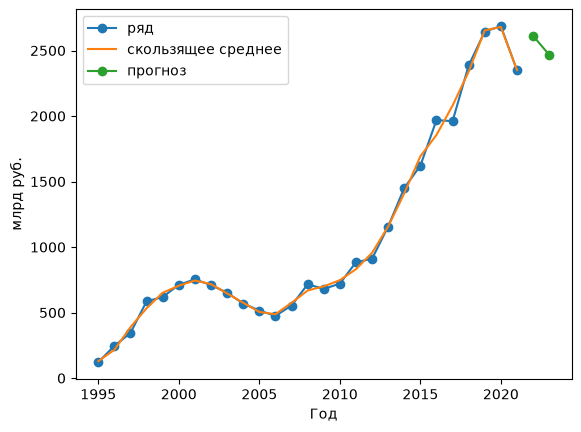

In [8]:
def forecast_ma(values, steps, n=5):
    values = list(values)
    for _ in range(steps):
        values.append(smooth(values)[-2] + (values[-1] - values[-2]) / n)
    return values[-steps:]


years = [y.index[-1] + 1, y.index[-1] + 2]
ma_forecast = pd.Series(forecast_ma(y, 2), index=years)
print(ma_forecast.round(1))

plt.plot(y, marker='o', label='ряд')
plt.plot(smoothed, label='скользящее среднее')
plt.plot(ma_forecast, marker='o', label='прогноз')
plt.xlabel('Год')
plt.ylabel('млрд руб.')
plt.legend()
plt.show()

### Экспоненциальное сглаживание

Метод Хольта учитывает тренд: $A_t$ — сглаженный уровень, $B_t$ — сглаженный прирост. Начальные значения $A_1 = y_1$, $B_1 = 0$.
$$A_t = \alpha y_t + (1 - \alpha)(A_{t-1} + B_{t-1}), \qquad B_t = \beta (A_t - A_{t-1}) + (1 - \beta) B_{t-1}, \qquad \hat{y}_{t+d} = A_t + d B_t$$
Параметры $\alpha$ и $\beta$ подбираю перебором с шагом 0.05 так, чтобы прогнозы на один шаг вперёд по имеющемуся ряду давали минимальную ошибку RMSE.

In [9]:
def holt(values, alpha, beta):
    A, B, pred = values.iloc[0], 0, []
    for value in values.iloc[1:]:
        pred.append(A + B)
        A_new = alpha * value + (1 - alpha) * (A + B)
        B = beta * (A_new - A) + (1 - beta) * B
        A = A_new
    return A, B, pd.Series(pred, index=values.index[1:])


def rmse(values, pred):
    return np.sqrt(((values.iloc[1:] - pred) ** 2).mean())


grid = np.arange(0.05, 1, 0.05)
error, alpha, beta = min((rmse(y, holt(y, a, b)[2]), a, b) for a in grid for b in grid)
print(f'alpha = {alpha:.2f}, beta = {beta:.2f}, RMSE = {error:.1f}')

alpha = 0.95, beta = 0.55, RMSE = 163.6


2022    2264.8
2023    2155.5
dtype: float64


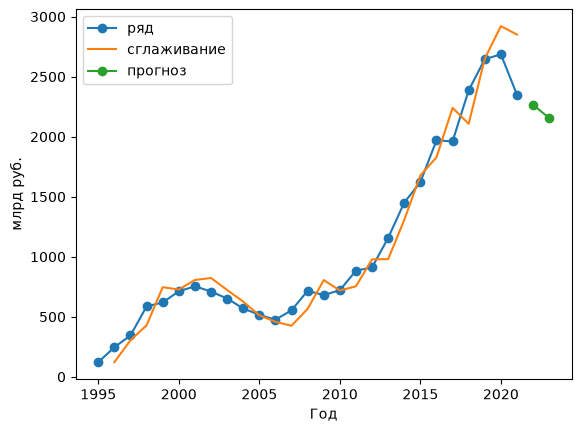

In [10]:
A, B, pred = holt(y, alpha, beta)
exp_forecast = pd.Series([A + B, A + 2 * B], index=years)
print(exp_forecast.round(1))

plt.plot(y, marker='o', label='ряд')
plt.plot(pred, label='сглаживание')
plt.plot(exp_forecast, marker='o', label='прогноз')
plt.xlabel('Год')
plt.ylabel('млрд руб.')
plt.legend()
plt.show()

### Результат

Взвешенное скользящее среднее убирает мелкие колебания, но почти повторяет ряд: кубический полином на 5 точках гибкий. Прогноз — 2612.4 млрд руб. на 2022 г. и 2466.7 на 2023 г. Он убывает, но выше фактического значения 2021 г. (2349), т.к. формула прогноза отталкивается от сглаженного значения 2020 г. (2679.8).

По методу Хольта минимальная RMSE = 163.6 при α = 0.95 и β = 0.55. Большое α означает, что модель почти полностью опирается на последнее значение ряда. Прогноз — 2264.8 и 2155.5 млрд руб., продолжение спада 2021 г.

Прогнозы двух методов отличаются на 300–350 млрд руб.: скользящее среднее начинает от сглаженного значения 2020 г., а метод Хольта — от фактического значения 2021 г.

## Вывод

Оба критерия показали, что в ряду просроченной задолженности поставщикам и подрядчикам есть тренд: уровни растут с 122 млрд руб. в 1995 г. до 2686 млрд руб. в 2020 г., с временным снижением в 2002–2006 гг. Метод Фостера–Стюарта показал ещё и тренд дисперсии, что совпадает с неоднородностью дисперсий в методе сравнения средних. Оба метода сглаживания дают убывающий прогноз на 2022–2023 гг., но на разных уровнях: по скользящему среднему 2612 и 2467 млрд руб. — выше фактического значения 2021 г., по методу Хольта 2265 и 2156 млрд руб. — ниже него.